# Youthful4Model CNNLSTM24h OC2



```
CNNLSTMModel(
 83   (hybridNetwork): Sequential(
 84     (0): Conv1d(61, 176, kernel_size=(1,), stride=(1,))
 85     (1): ReLU()
 86     (2): LSTM(176, 176, num_layers=3, dropout=0.5255918882358939)
 87   )
 88   (endLinearLayer): Linear(in_features=176, out_features=24, bias=True)
# 89 )
```



In [ ]:
config = {
    "alphaRMS": 0.8878535830123158,
    "batch_size": 128,
    "device": "cuda",
    "dimTrValDataSet": 0.8135103108199945,
    "dropout": 0.5255918882358939,
    "eps": 0.00000001809781643808,
    "input_size": 61,
    "l1_factor": 0.00001788764196672363,
    "l1_lambda": 0.00985428675707348,
    "learning_rateAdam": 0.000654610999498754,
    "learning_rateRMS": 0.04441832592851753,
    "method": "random",
    "metric": {
        "goal": "minimize",
        "name": "avg_TestLoss",
        "min_delta": 0.0035540167852985117
    },
    "momentumRMS": 0.726408866481537,
    "nStepsAhead": 24,
    "num_epochs": 633,
    "num_lstm_layers": 3,
    "optimizer": "Adam",
    "patience": 38,
    "scheduler": "ReduceLROnPlateau",
    "scheduler_factor": {
        "CosineAnnealingWarmRestarts": 1.1189226291910723,
        "ReduceLROnPlateau": 0.7502387107470798
    },
    "scheduler_min_lr": {
        "CosineAnnealingWarmRestarts": 0.0000986804709547241,
        "ReduceLROnPlateau": 0.00025800234809786196
    },
    "scheduler_patience": {
        "CosineAnnealingWarmRestarts": 5.485778505433907,
        "ReduceLROnPlateau": 8.645318720669717
    },
    "test_split_size": 0.14632058556123811,
    "trW": 20,
    "vlWl": 17,
    "weight_decay": {
        "Adam": 0.0008131241983869834,
        "RMS": 0.004928825586952906
    },
    "window_size": 176
}



In [ ]:
pip install --upgrade wandb


In [ ]:
import pandas as pd
import torch
from torch import nn
import torch.nn.functional as F
import torch.optim as optim
from torch.utils.data import TensorDataset, DataLoader
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score
import seaborn as sns
import matplotlib.pyplot as plt
import numpy as np
import wandb
from sklearn.preprocessing import MinMaxScaler
import statistics as stat
import time

from google.colab import drive
drive.mount('/content/drive')
wandb.login()
device = torch.device("cuda:0" if torch.cuda.is_available() else "cpu")

class CNNLSTMModel(nn.Module):

  def __init__(self, input_size, num_lstm_layers, dropout,
               sequence_length,nStepsAhead):
    super().__init__()

    # model definition
    self.hybridNetwork = nn.Sequential(
        nn.Conv1d(in_channels=input_size,
                  out_channels=sequence_length,
                  kernel_size=1),
        nn.ReLU(),
        nn.LSTM(input_size=sequence_length,
                hidden_size=sequence_length,
                num_layers=num_lstm_layers,
                dropout=dropout,
                batch_first=False),
    )
    self.endLinearLayer = nn.Linear(sequence_length,nStepsAhead)

  def forward(self, x):
    # Apply CNN layers
    x = x.permute(0, 2, 1)
    x = self.hybridNetwork[0](x)  # Conv1d
    x = self.hybridNetwork[1](x)  # ELU activation

    # Permute the dimensions for LSTM
    x = x.permute(2, 0, 1)

    # Apply LSTM layers
    x, (hidden, cell) = self.hybridNetwork[2](x)

    # Only take the output from the last time-step
    x = x[-1, :, :]

    # Apply final linear layer
    x = self.endLinearLayer(x)
    return x

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [ ]:
KPITSyou4 = pd.read_csv("/content/drive/MyDrive/Colab Notebooks/ResultOutput/RWIN_CNNLSTM1/LC2_prediction[tr&vlW-24h-noOPT]/OPTRWIN_CNNLSTM (LC2[tr&vlW-24h-noOPT])/youthful-sweep4KPI.csv")
predTSyou4 = pd.read_csv("/content/drive/MyDrive/Colab Notebooks/ResultOutput/RWIN_CNNLSTM1/LC2_prediction[tr&vlW-24h-noOPT]/OPTRWIN_CNNLSTM (LC2[tr&vlW-24h-noOPT])/youthful-sweep4predictions_t2cs7uv6.csv")



# Dataset download
dataSetClean = pd.read_csv("/content/drive/MyDrive/Colab Notebooks/FeatureEngineering&DATA/dataSetIMRCleaned.csv")
hlc3 = dataSetClean['hlc3']
dataSetClean.drop(labels=['hlc3'], axis=1, inplace=True)
oc2 = (dataSetClean['close'] + dataSetClean['open'] )/2
dataSetClean.insert(0, 'oc2', oc2)


# Dataloading (sliding windows)
config["input_size"] = dataSetClean.shape[1]  # with 1 have number of features

# Normalize
scaler = MinMaxScaler()
scaler.fit(dataSetClean)
dataSet = scaler.transform(dataSetClean)
dataSet = pd.DataFrame(dataSet)
youthfu4lModel = CNNLSTMModel(config["input_size"],config["num_lstm_layers"], config["dropout"],config["window_size"],config["nStepsAhead"])
model_path = '/content/drive/MyDrive/Colab Notebooks/ResultOutput/RWIN_CNNLSTM1/LC2_prediction[tr&vlW-24h-noOPT]/OPTRWIN_CNNLSTM (LC2[tr&vlW-24h-noOPT])/youthful-sweep4OPTRWIN_CNNLSTM (LC2[tr&vlW-24h-noOPT]t2cs7uv6.pth'
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
youthfu4lModel.load_state_dict(torch.load(model_path, map_location=device))
youthfu4lModel = youthfu4lModel.to(device)
youthfu4lModel.eval()
KPITSyou4.head()

,Unnamed: 0,MSE,RMSE,R2,ACCURACY,MAE,AV-AE,Explane variance,ACPER2,ACPER5,APE,Dataset
0,0,0.000921,0.030349,0.986741,-58.211612,0.023657,0.019507,0.986741,11.493056,27.994792,0.379548,Training
1,1,0.000599,0.024475,0.991098,73.132917,0.020042,0.017630,0.991101,11.341146,26.848958,-0.049145,Validation
2,2,0.000187,0.013658,0.983748,96.557466,0.010854,0.009141,0.983817,41.009852,85.283251,-0.001806,Test


# service functions

In [ ]:
def predictionsPlot(predTS, start,end,name):
    # Ensure start and end are integers
    start = int(start)
    end = int(end)

    y_true_flat = np.array(predTS["targets"])
    y_pred_flat = np.array(predTS["predictions"])
    plt.figure(figsize=(55, 25))
    if start == -1 and end == -1:
        plt.plot(y_true_flat[:-1], label='True Value')
        plt.plot(y_pred_flat[:-1], label=name)
    else:
        plt.plot(y_true_flat[start:end], label='True Value')
        plt.plot(y_pred_flat[start:end], label=name)
        adjusted_start = start - (start % 24)
        for i in range(adjusted_start, end, 24):
            if i >= start:
                plt.axvline(x=i-start, color='k', linestyle='--')
    plt.title('Results')
    plt.xlabel('Time Step')
    plt.ylabel('Value')
    plt.legend()
    plt.legend(fontsize='large')
    plt.show()

In [ ]:
# inserire anche funzioni di calcolo delle KPI
from sklearn.metrics import median_absolute_error,mean_absolute_error,explained_variance_score
class ResultManager:
  def __init__(self, dfResult):

      self.dfResult = dfResult
      self.mse = 0
      self.rmse = 0
      self.r2 = 0
      self.acc = 0
      self.mae = 0
      self.aae = 0
      self.evs = 0
      self.acper2 = 0
      self.acper5 = 0
      self.ape = 0

  def resultPerformance(self):
    return pd.DataFrame({
          "MSE": [self.mse],
          "RMSE": [self.rmse],
          "R2": [self.r2],
          "ACCURACY": [self.acc],
          "MAE" : [self.mae],
          "AV-AE": [self.aae],
          "Explane variance":[self.evs],
          "ACPER2": [self.acper2],
          "ACPER5": [self.acper5],
          "APE": [self.ape]
      })
  def setMse(self, mse):
    self.mse = mse
  def setRmse(self, rmse):
    self.rmse = rmse
  def setR2(self, r2):
    self.r2 = r2
  def setAcc(self,acc):
    self.acc = acc
  def setMae(self,mae):
    self.mae = mae
  def setAae(self,aae):
    self.aae = aae
  def setEvs(self,evs):
    self.evs = evs
  def setAcper2(self,acper2):
    self.acper2= acper2
  def setAcper5(self,acper5):
    self.acper5= acper5
  def setApe(self,ape):
    self.ape=ape

  def acper_complessivo(self,val):
    threshold = val
    # Calcolo del limite inferiore e superiore
    lower_bound = self.dfResult["targets"] - (threshold * self.dfResult["targets"])
    upper_bound = self.dfResult["targets"] + (threshold * self.dfResult["targets"])
    # Controllo se y_pred è tra i limiti e calcolo la percentuale di True
    matches = (self.dfResult["predictions"] >= lower_bound) & (self.dfResult["predictions"] <= upper_bound)
    # Calcolo la percentuale di corrispondenze soddisfacenti la condizione
    percentuale_acper = (matches.sum() / len(self.dfResult)) * 100
    return percentuale_acper


  def overallKpiCompute(self):

    self.mse = mean_squared_error(self.dfResult["targets"],self.dfResult["predictions"])
    self.rmse = mean_squared_error(self.dfResult["targets"],self.dfResult["predictions"], squared=False)
    self.r2 = r2_score(self.dfResult["targets"],self.dfResult["predictions"])
    self.mae = mean_absolute_error(self.dfResult["targets"],self.dfResult["predictions"])
    self.aae = median_absolute_error(self.dfResult["targets"],self.dfResult["predictions"])
    self.evs = explained_variance_score(self.dfResult["targets"],self.dfResult["predictions"])
    self.acper2 = self.acper_complessivo(0.02)
    self.acper5 = self.acper_complessivo(0.05)
    self.ape =  np.mean((np.abs(self.dfResult["predictions"]) - self.dfResult["targets"]) / np.array(self.dfResult["targets"]), axis=0)

    #  compute accuracy
    real = self.dfResult["targets"]
    predict = self.dfResult["predictions"]
    percentage = 1 - np.sqrt(np.mean(np.square((real - predict) / real)))
    self.acc =  percentage * 100
    KpiDf = self.resultPerformance()
    # calcola anche la accuracy
    return KpiDf




  def mseStepByStepDf(self,dfPredTargetMSE):

    for i in range(len(dfPredTargetMSE)):
    # Ensure the true and predicted values are passed as lists
      mse = mean_squared_error([dfPredTargetMSE.at[i,"targets"]], [dfPredTargetMSE.at[i,"predictions"]])
      dfPredTargetMSE.at[i, "mse"] = mse

    mse_mean = mean_squared_error(dfPredTargetMSE["targets"], dfPredTargetMSE["predictions"])
    return dfPredTargetMSE

  def tableResultWandb(self,typeDS):
    true_values = self.dfResult["targets"]
    predictions = self.dfResult["predictions"]
    results_table = wandb.Table(columns=[f"True Values_{typeDS}", f"Predictions_{typeDS}"])

    # Aggiungi i dati alla tabella
    for true, pred in zip(true_values, predictions):
        results_table.add_data(true, pred)

    # Log la tabella su wandb
    wandb.log({"Prediction vs True": results_table})

  def tableResultCSV(self,typeDS):
    true_values = self.dfResult["targets"]
    predictions = self.dfResult["predictions"]
    df = pd.DataFrame({"True Values": true_values, "Predictions": predictions})
    path_to_save = "/content/drive/MyDrive/Colab Notebooks/ResultOutput/RWIN_CNNLSTM1/LC2_prediction[tr&vlW-24h-noOPT]"
    filename = f"RWIN_CNNLSTMohlc4_output_{typeDS}.csv"
    full_path = f"{path_to_save}{filename}"
    df.to_csv(full_path, index=False)
    print("Uploaded {filename} to drive")

In [ ]:
def flatten_if_nested(lst):

    # Initialize an empty list to store the flattened elements
    flat_list = []

    # Iterate through each element in the input list
    for item in lst:
        # If the element is a list, extend the flat list with the flattened version of this element
        if isinstance(item, list):
            flat_list.extend(flatten_if_nested(item))
        # If the element is not a list, simply append it to the flat list
        else:
            flat_list.append(item)

    return flat_list
# Example usage:
nested_list = [1, [2, 3], [4, [5, 6, [7]]], 8]
flat_list = flatten_if_nested(nested_list)
print(flat_list)

[1, 2, 3, 4, 5, 6, 7, 8]


In [ ]:
def slidingWindowsAhead(df, windowSize, nStepsAhead,dimTrValDataSet):
  x = []
  y = []
  dataLen = df.shape[0] # n rows
  for i in range(windowSize, dataLen, nStepsAhead):
      if i + nStepsAhead > dataLen:
          break  # If we do not have enough data to predict further, we break the loop.
    # '_x' will contain 'windowSize' values as input data
      _x = df.iloc[i-windowSize:i].values
    # '_y' will contain 'nStepsAhead' values as labels
      _y = df.iloc[i:i+nStepsAhead, 0].values
      x.append(_x)
      y.append(_y)

  # convert windows in tensor
  np.array(x)
  np.array(y)
  trVlWnum = int(len(x) * dimTrValDataSet)
  testWnum = len(x) - trVlWnum  # Remaining data for testing

  trVlX = x[:trVlWnum]
  testX = x[trVlWnum:]
  trVlY = y[:trVlWnum]
  testY = y[trVlWnum:]

  print("_______ Dim mX & mY ______")
  print(f"dim mX:{len(x)} dim mY:{len(y)}")
  print("_____Dimension X & Y _____")
  print(f"dim trValX:{len(trVlX)} --- dim trValY:{len(trVlY)} ")

  print(f"dim testX:{len(testX)} --- dim testY:{len(testY)} ")

  # Convert from numpy arrays to torch tensors
  trVlX_tensor = torch.tensor(trVlX, dtype=torch.float32)
  trVlY_tensor = torch.tensor(trVlY, dtype=torch.float32).unsqueeze(1)
  testX_tensor = torch.tensor(testX, dtype=torch.float32)
  testY_tensor = torch.tensor(testY, dtype=torch.float32).unsqueeze(1)

  print("_____Dimension X & Y tensor _____")
  print(f"dim TR&VAL X:{trVlX_tensor.shape} --- dim TR&VAL Y:{trVlY_tensor.shape} ")
  print(f"dim TEST X:{testX_tensor.shape} --- dim TEST Y:{testY_tensor.shape} ")

  return trVlX_tensor,trVlY_tensor,testX_tensor,testY_tensor

In [ ]:
class TimeSeriesDataset(torch.utils.data.Dataset):
    def __init__(self, X_data, y_data):
        super(). __init__()
        self.X_data = X_data
        self.y_data = y_data

    def __len__(self):
        return len(self.X_data)

    def __getitem__(self, index):
        return self.X_data[index], self.y_data[index]


def getDataSet(x,y):
    dataSet = TimeSeriesDataset(x, y)
    return dataSet


def getDataLoader(dataSet,config):
  loader = DataLoader(dataset=dataSet,
                          batch_size=config["batch_size"],
                          shuffle=False)
  return loader

# model pipeline

In [ ]:

def testLoop(model, testX_tensor,testY_tensor,config,loss_fn):
  all_predictionsTS = []
  all_targetsTS = []
  all_input = []
  testLoss = 0
  model.eval()
  dataSetTS = getDataSet(testX_tensor,testY_tensor)
  test_loader =getDataLoader(dataSetTS,config)
  with torch.no_grad():
    for batch_idx, (data, target) in enumerate(test_loader):
      data, target = data.to(config["device"]), target.to(
        config["device"])
      target = target.squeeze(1)
      output = model(data)

      loss = loss_fn(output, target)

      testLoss += loss.item()

      all_predictionsTS.extend(
        output.squeeze().tolist())  # Flatten and accumulate predictions
      all_targetsTS.extend(
        target.squeeze().tolist())
      all_input.extend(
        data.squeeze().tolist())

  resultALL = pd.DataFrame({
        "input": all_input,
        "targets": all_targetsTS,
        "predictions": all_predictionsTS
        })

  resultTS = pd.DataFrame({
        "targets": flatten_if_nested(all_targetsTS),
        "predictions": flatten_if_nested(all_predictionsTS)
        })
  avg_loss = testLoss / len(test_loader)
  #print(f"TestLoss: {avg_loss}")
  return avg_loss,resultTS,resultALL

In [ ]:

    # Make the data
trVlX_tensor,trVlY_tensor,testX_tensor,testY_tensor = slidingWindowsAhead(dataSet, 176, 24,0.8135103108199945)
    # Make lossFunction
loss_fn = torch.nn.MSELoss(reduction='mean')

    # Make prediction over TrValDataSet and colect input,target,pred,KPI
avg_lossTRVAL,resultTRVAL,resultTRALL = testLoop(youthfu4lModel,trVlX_tensor,trVlY_tensor,config,loss_fn)

print(f"avg_lossTRVAL: {avg_lossTRVAL}")
resultManagerTRVAL =  ResultManager(resultTRVAL)
youth4KPI_TRVAL = resultManagerTRVAL.overallKpiCompute()



    # Make prediction over TestSet and colect input,target,pred,KPI

avg_lossTS,resultTS,resultTSALL = testLoop(youthfu4lModel,testX_tensor,testY_tensor,config,loss_fn)

print(f"avg_lossTS: {avg_lossTS}")
resultManagerTS =  ResultManager(resultTS)
youth4KPI_TS = resultManagerTS.overallKpiCompute()





_______ Dim mX & mY ______
dim mX:2159 dim mY:2159
_____Dimension X & Y _____
dim trValX:1756 --- dim trValY:1756 
dim testX:403 --- dim testY:403 
_____Dimension X & Y tensor _____
dim TR&VAL X:torch.Size([1756, 176, 61]) --- dim TR&VAL Y:torch.Size([1756, 1, 24]) 
dim TEST X:torch.Size([403, 176, 61]) --- dim TEST Y:torch.Size([403, 1, 24]) 
avg_lossTRVAL: 0.0007972402288162682
avg_lossTS: 0.0002175877980334917


RESULT_ALL

In [ ]:
resultTRALL.head()

,input,targets,predictions
0,"[[0.0768636167049408, 0.07649219036102295, 0.0...","[0.08264148980379105, 0.08279538154602051, 0.0...","[0.1020854189991951, 0.10213224589824677, 0.10..."
1,"[[0.05784960091114044, 0.05754454806447029, 0....","[0.09330222010612488, 0.09344740211963654, 0.0...","[0.11239119619131088, 0.11242695897817612, 0.1..."
2,"[[0.06758397072553635, 0.06847278773784637, 0....","[0.10400599241256714, 0.10533440858125687, 0.1...","[0.11889852583408356, 0.11892682313919067, 0.1..."
3,"[[0.06901314854621887, 0.0676170289516449, 0.0...","[0.10539901256561279, 0.1043069064617157, 0.10...","[0.11510501801967621, 0.11513743549585342, 0.1..."
4,"[[0.08299446105957031, 0.08306114375591278, 0....","[0.11604728549718857, 0.11576440930366516, 0.1...","[0.12679201364517212, 0.12681172788143158, 0.1..."


KPI_TRVAL

In [ ]:
youth4KPI_TRVAL.head()

,MSE,RMSE,R2,ACCURACY,MAE,AV-AE,Explane variance,ACPER2,ACPER5,APE
0,0.000811,0.028473,0.988318,-inf,0.023837,0.022109,0.991746,14.281986,31.779138,inf


KPI_TS

In [ ]:
youth4KPI_TS.head()

,MSE,RMSE,R2,ACCURACY,MAE,AV-AE,Explane variance,ACPER2,ACPER5,APE
0,0.000176,0.013285,0.984416,96.615155,0.010578,0.009053,0.984545,42.866005,85.763027,-0.000526


In [ ]:
resultTRALL["input"]


0       [[0.0768636167049408, 0.07649219036102295, 0.0...
1       [[0.05784960091114044, 0.05754454806447029, 0....
2       [[0.06758397072553635, 0.06847278773784637, 0....
3       [[0.06901314854621887, 0.0676170289516449, 0.0...
4       [[0.08299446105957031, 0.08306114375591278, 0....
                              ...                        
1751    [[0.20308753848075867, 0.2029404640197754, 0.2...
1752    [[0.20274564623832703, 0.20249991118907928, 0....
1753    [[0.1990426629781723, 0.19919128715991974, 0.1...
1754    [[0.20590361952781677, 0.2027159035205841, 0.2...
1755    [[0.21384268999099731, 0.2137545943260193, 0.2...
Name: input, Length: 1756, dtype: object

# CHARTS

--> trainingValidation set

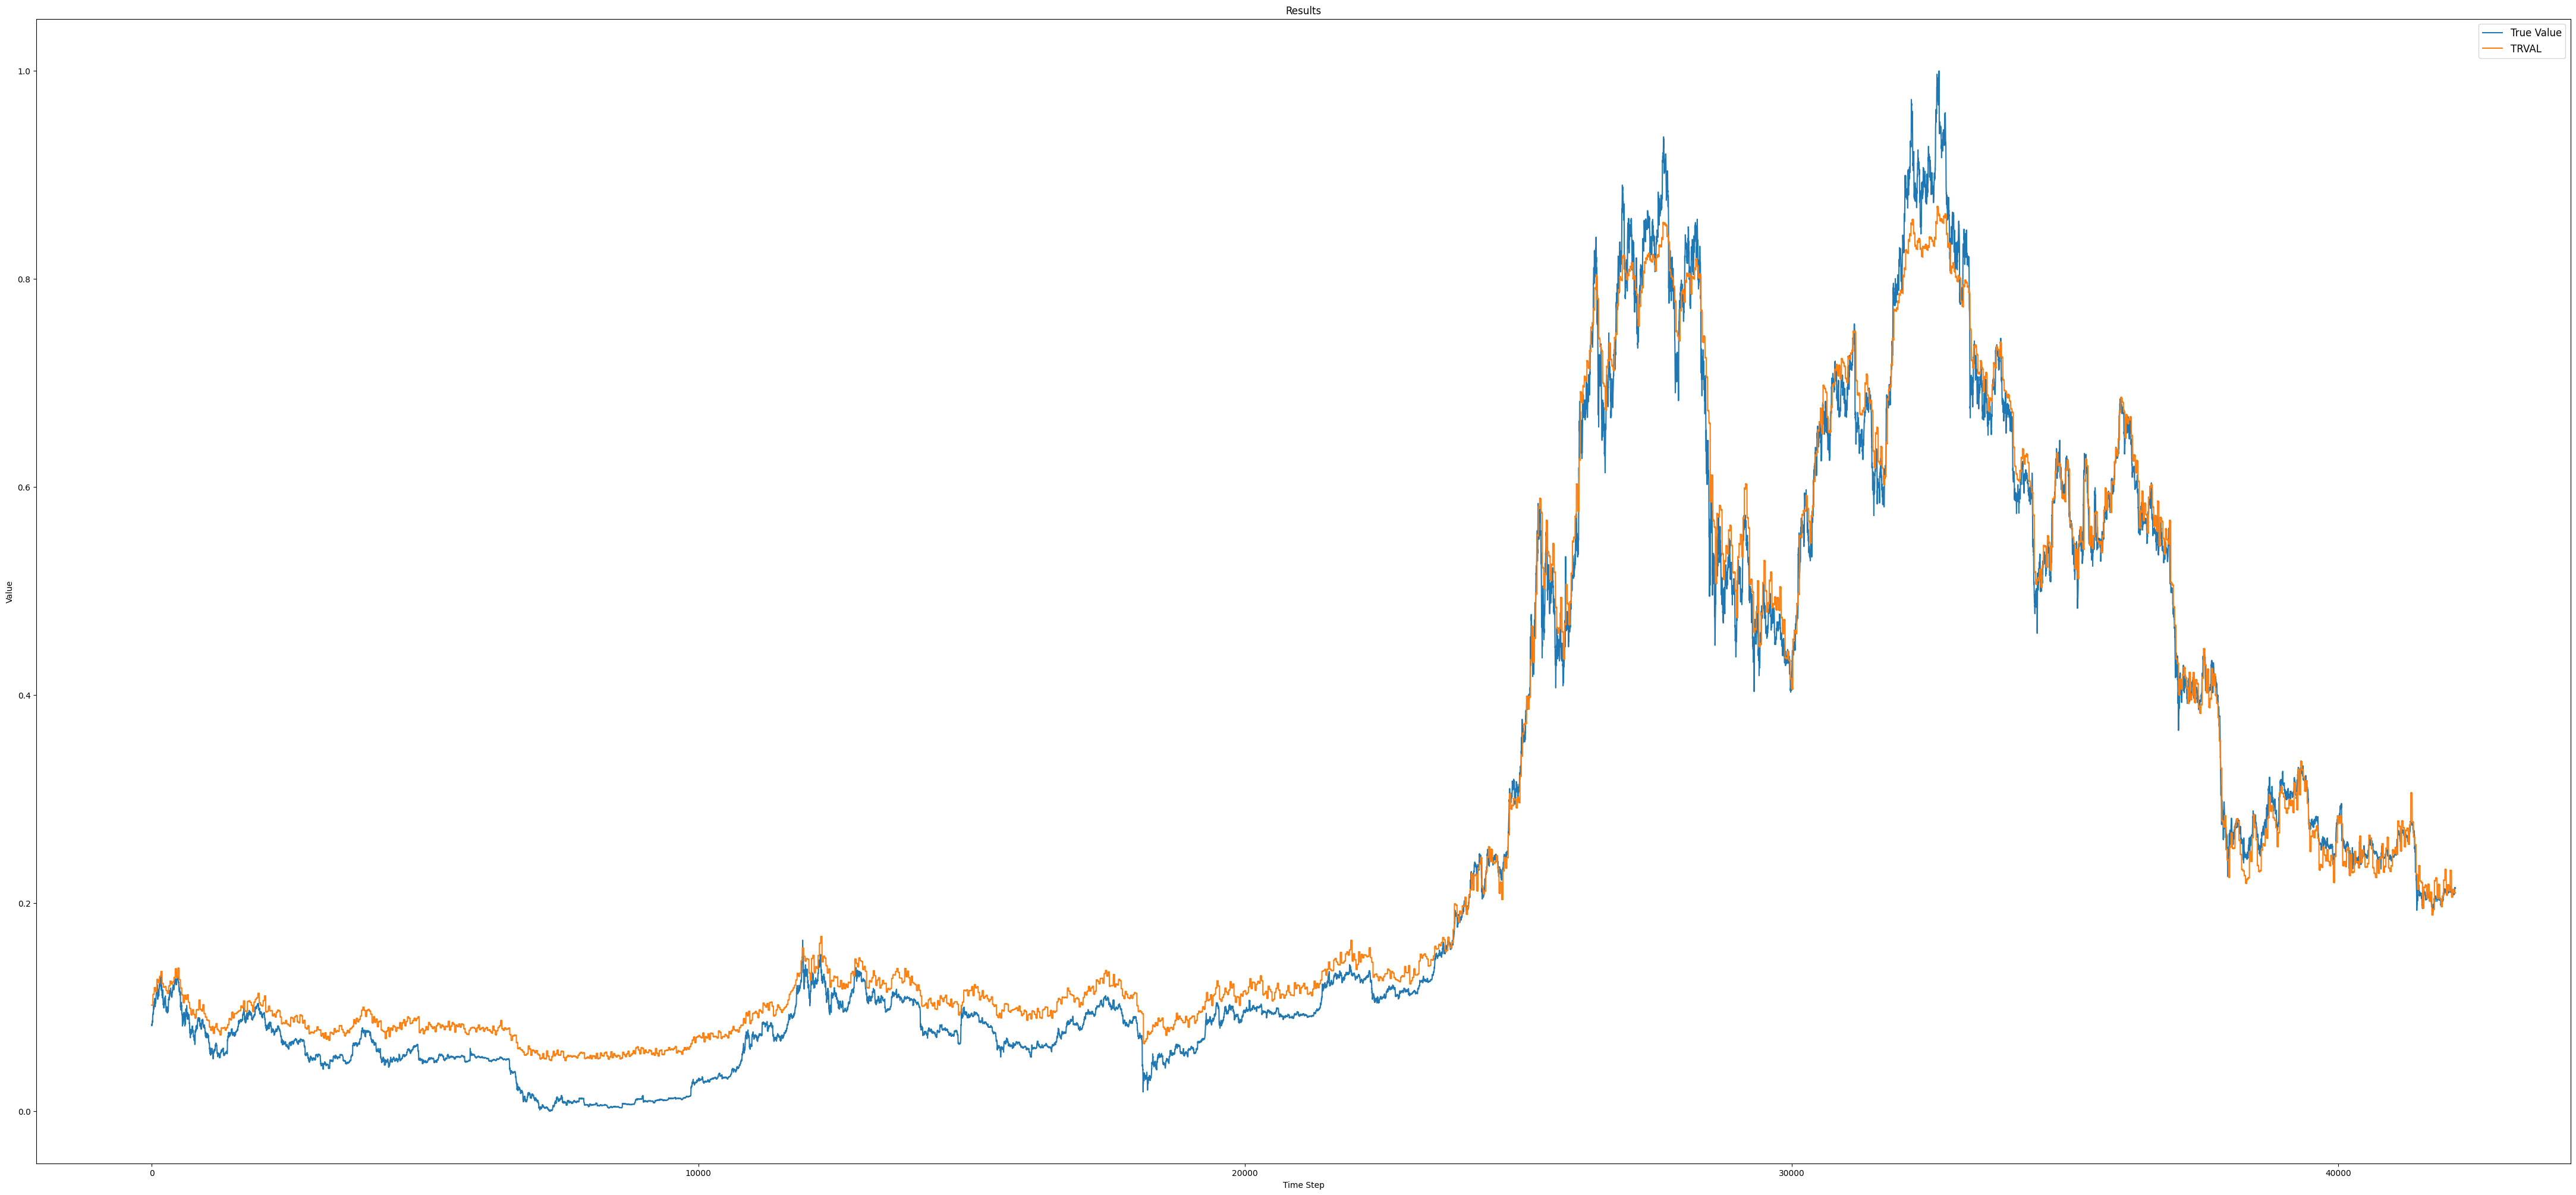

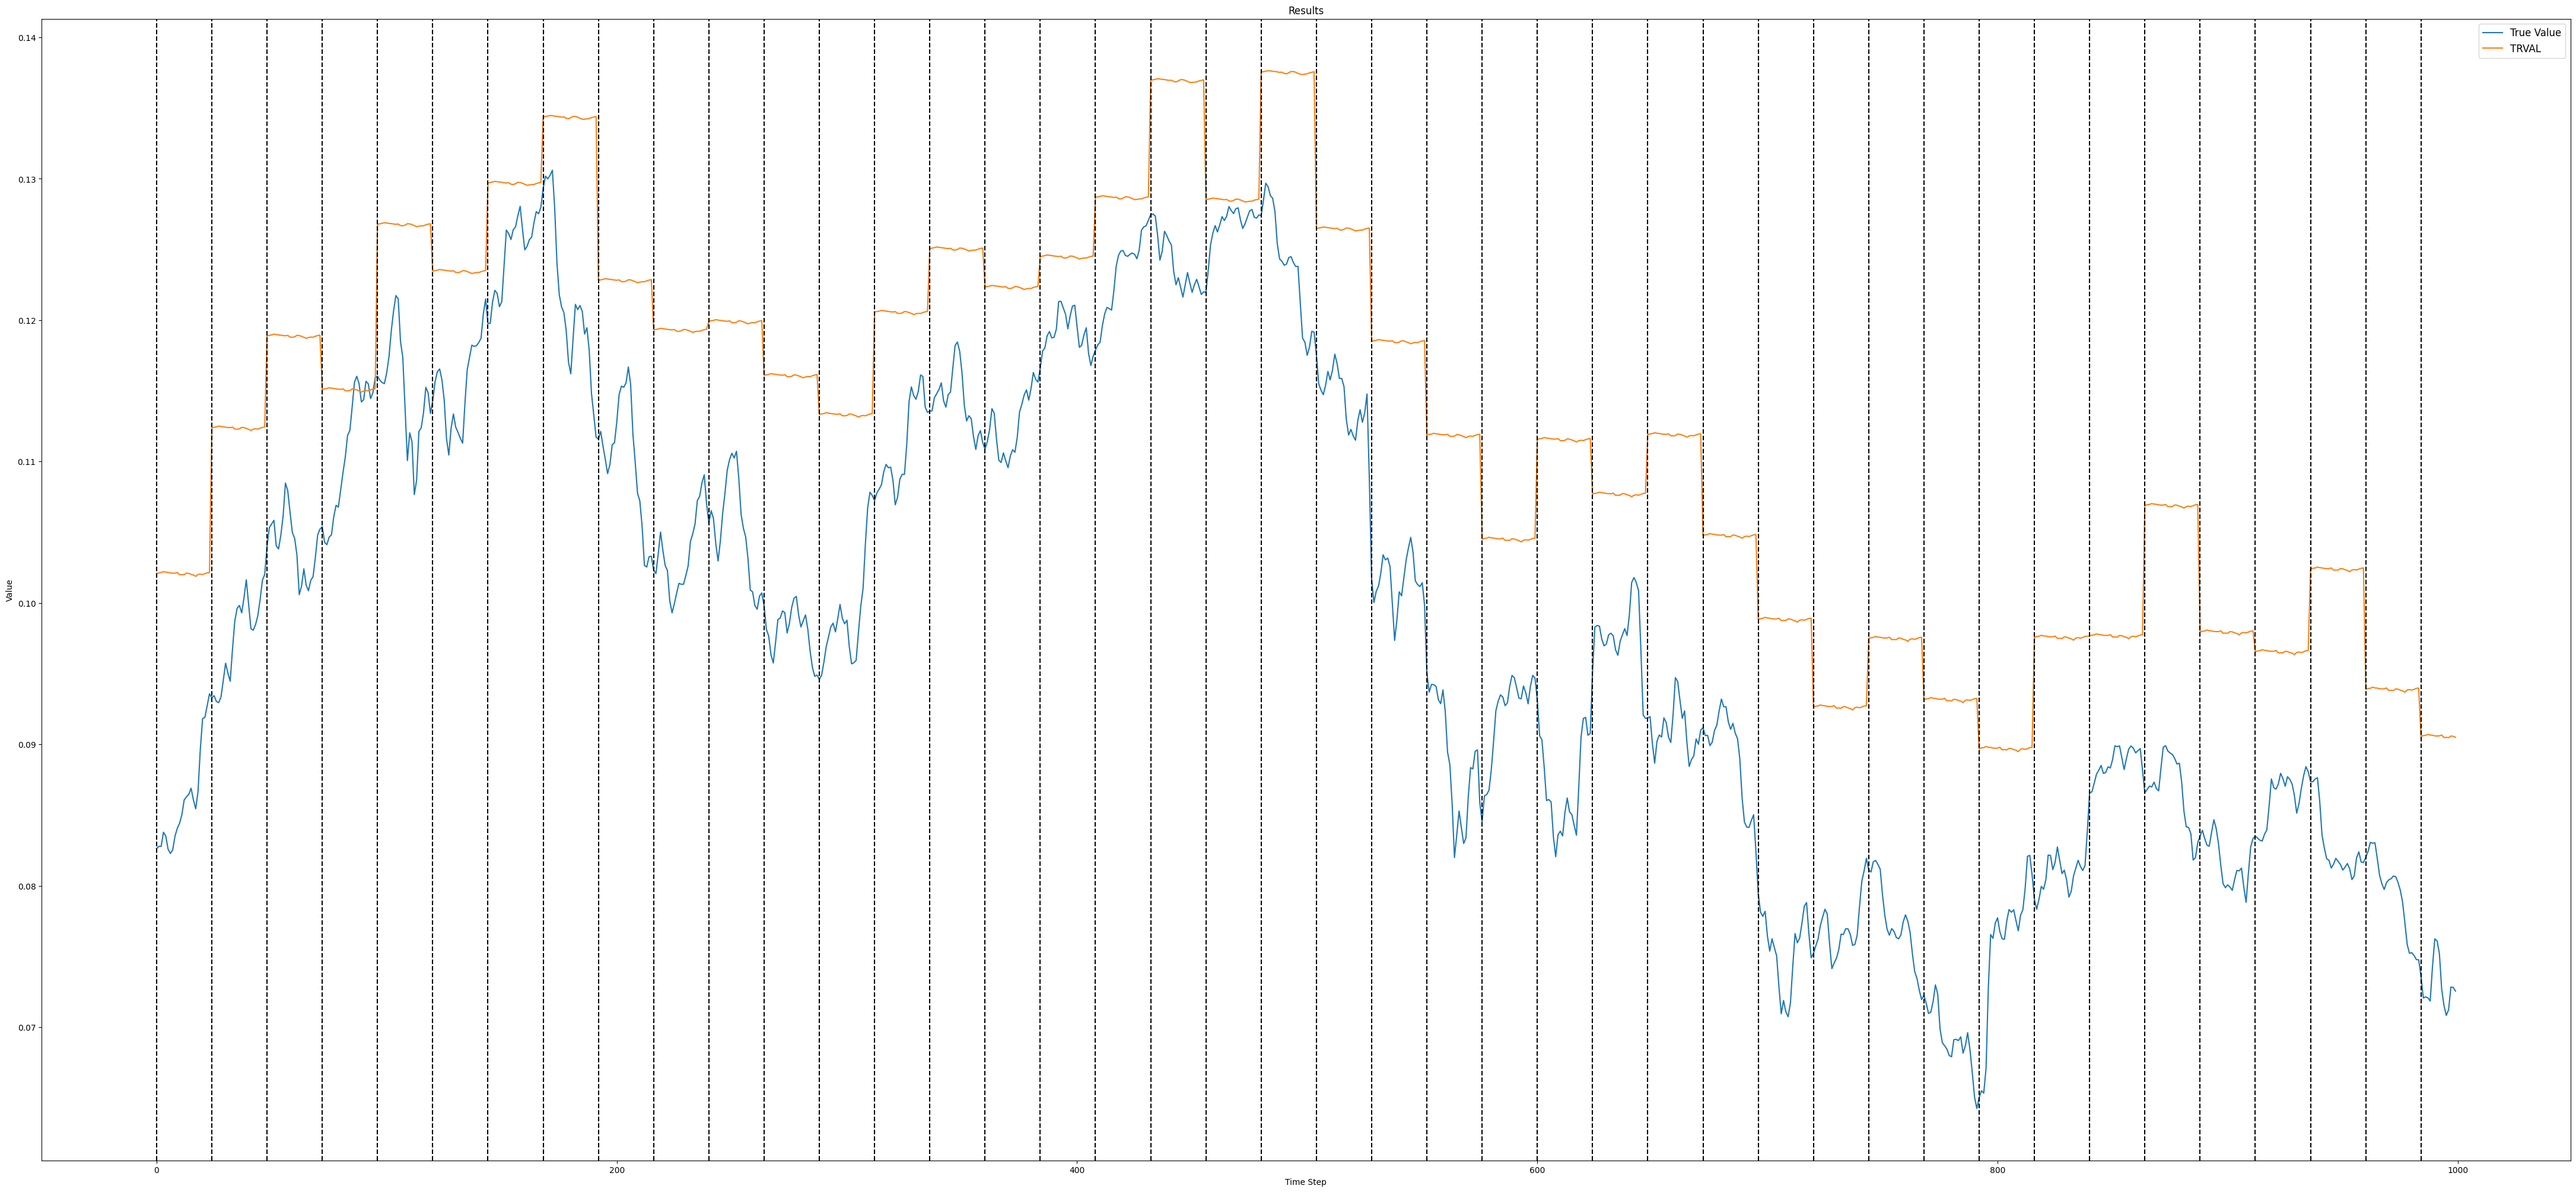

Mean MSE over dataset: 0.0008107169897079117


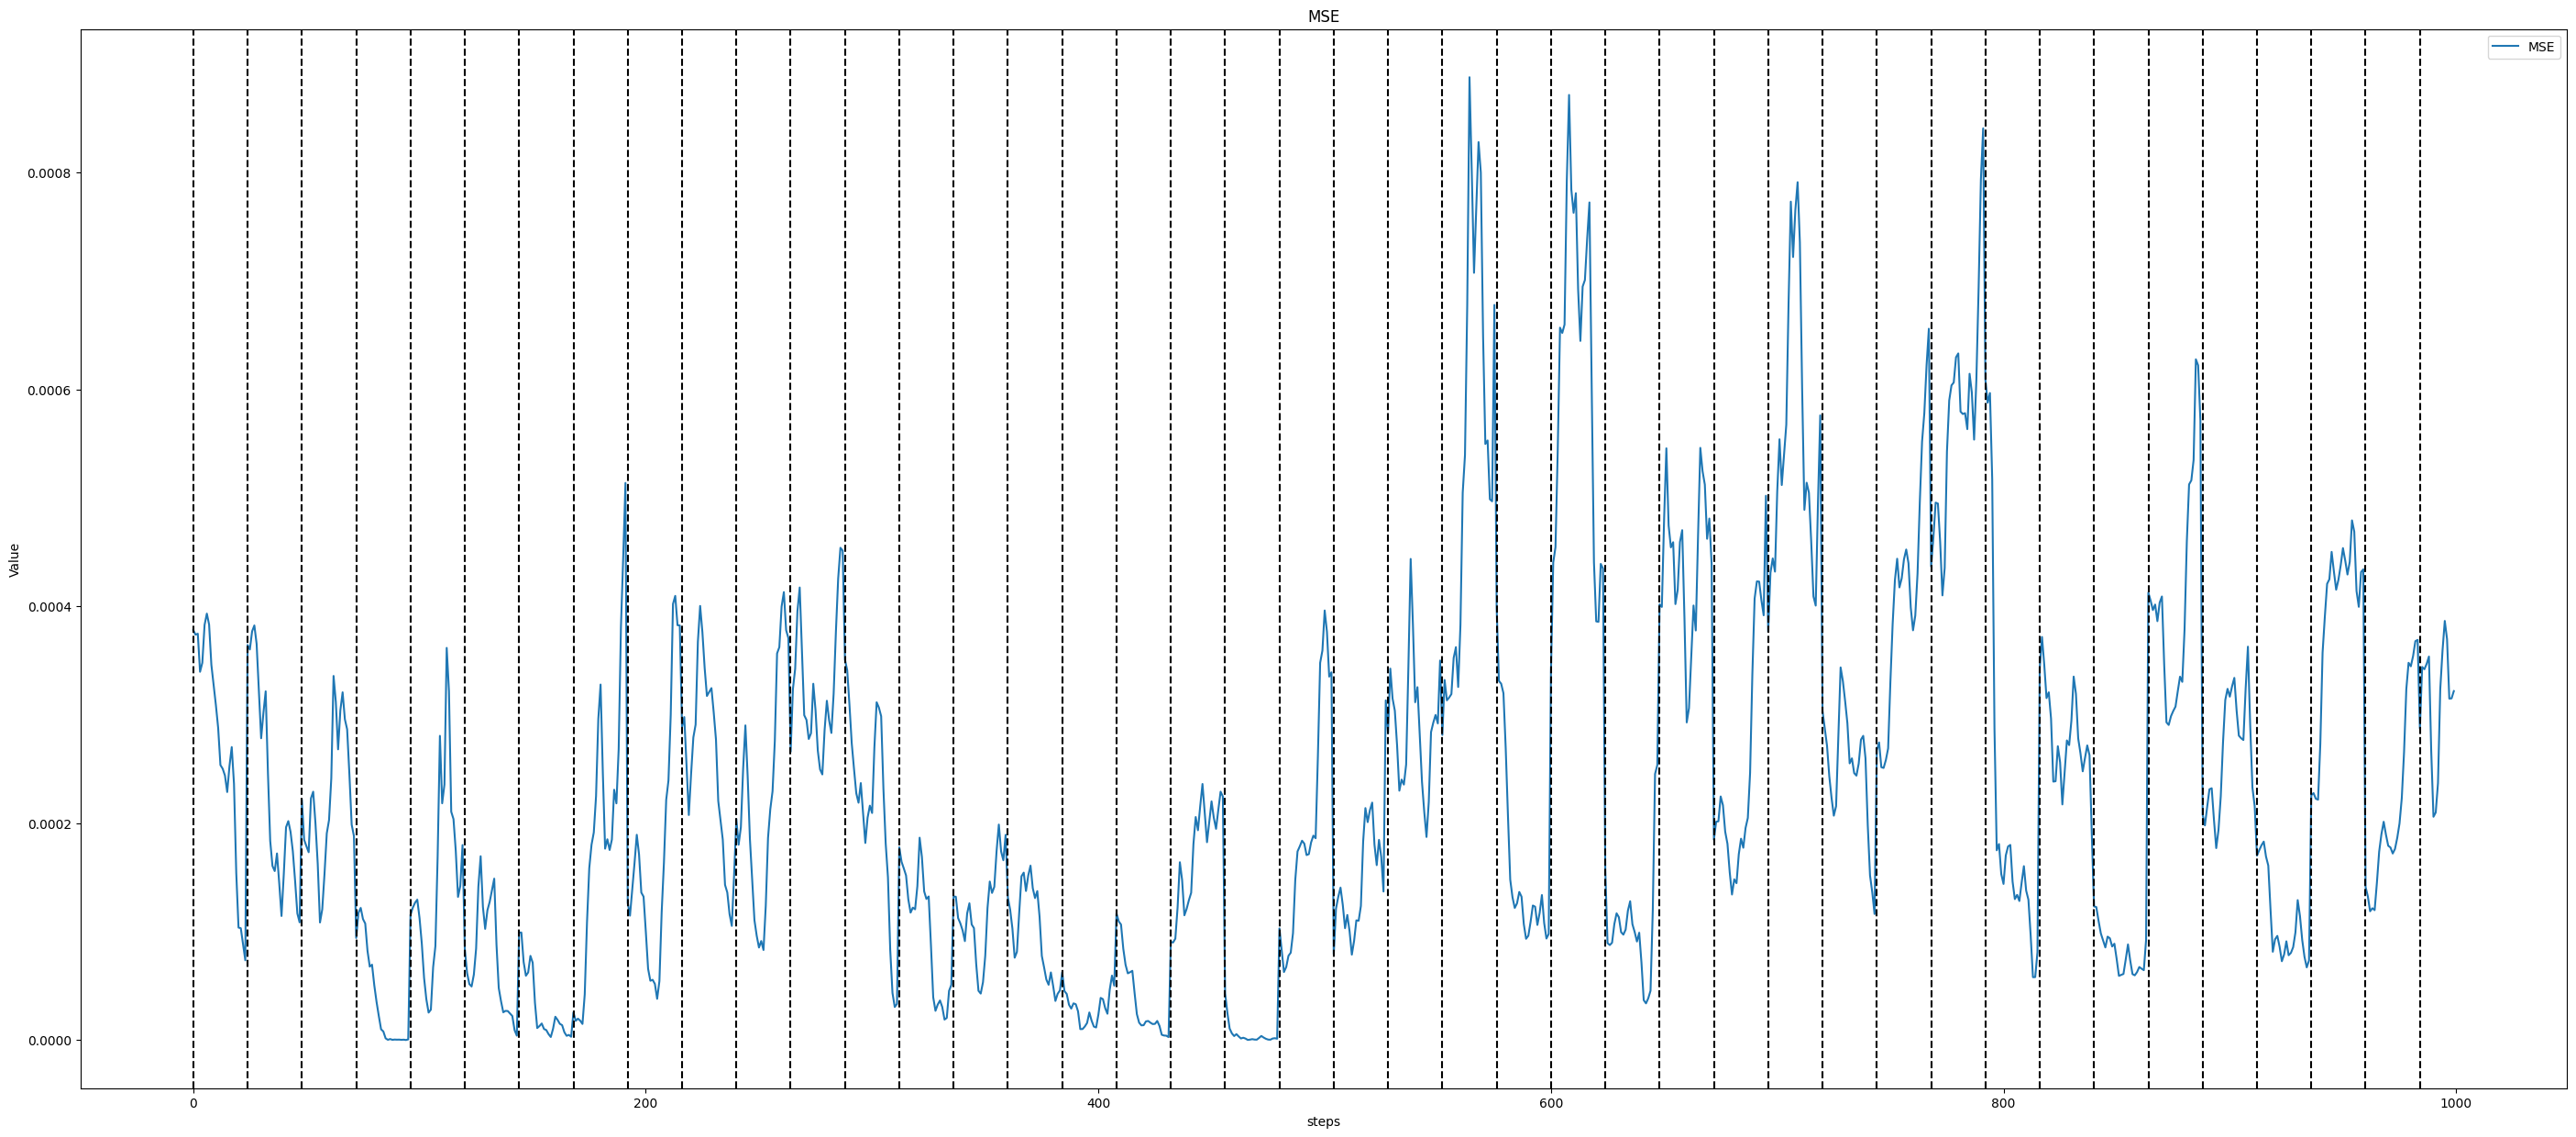

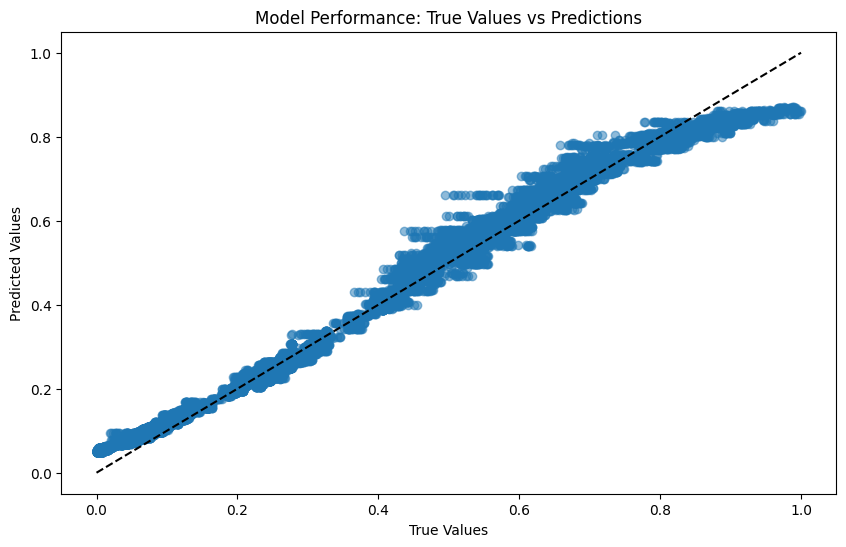

In [ ]:
def predictionsPlot(predTS, start,end,name):
    # Ensure start and end are integers
    start = int(start)
    end = int(end)

    y_true_flat = np.array(predTS["targets"])
    y_pred_flat = np.array(predTS["predictions"])
    plt.figure(figsize=(55, 25))
    if start == -1 and end == -1:
        plt.plot(y_true_flat[:-1], label='True Value')
        plt.plot(y_pred_flat[:-1], label=name)
    else:
        plt.plot(y_true_flat[start:end], label='True Value')
        plt.plot(y_pred_flat[start:end], label=name)
        adjusted_start = start - (start % 24)
        for i in range(adjusted_start, end, 24):
            if i >= start:
                plt.axvline(x=i-start, color='k', linestyle='--')
    plt.title('Results')
    plt.xlabel('Time Step')
    plt.ylabel('Value')
    plt.legend()
    plt.legend(fontsize='large')
    plt.show()

def msePlot(start,end,resultManager,resultTRVAL):
    dfPredTargetMSE = resultManager.mseStepByStepDf(resultTRVAL)
    mse_mean = mean_squared_error(dfPredTargetMSE["targets"], dfPredTargetMSE["predictions"])
    print(f"Mean MSE over dataset: {mse_mean}")
    plt.figure(figsize=(35, 15))
    plt.plot(dfPredTargetMSE["mse"].iloc[start:end], label='MSE')  # Corrected line
      # Insert a vertical line every 24 steps

    for i in range(start, end, config["nStepsAhead"]):
      plt.axvline(x=i, color='k', linestyle='--')
    plt.title('MSE')
    plt.xlabel('steps')
    plt.ylabel('Value')
    plt.legend()
    plt.show()

def scatter(predTS):
    y_true_flat = np.array(predTS["targets"])
    y_pred_flat = np.array(predTS["predictions"])

    # Convert to NumPy arrays
    y_true_flat = np.array(y_true_flat)
    y_pred_flat = np.array(y_pred_flat)

    # Scatter plot
    plt.figure(figsize=(10, 6))
    plt.scatter(y_true_flat, y_pred_flat, alpha=0.5)
    plt.title('Model Performance: True Values vs Predictions')
    plt.xlabel('True Values')
    plt.ylabel('Predicted Values')

    # Plot the perfect prediction line
    max_val = max(y_true_flat.max(), y_pred_flat.max())
    min_val = min(y_true_flat.min(), y_pred_flat.min())
    plt.plot([min_val, max_val], [min_val, max_val], 'k--')

    plt.show()

predictionsPlot(resultTRVAL,-1,-1,"TRVAL")
predictionsPlot(resultTRVAL,0,1000,"TRVAL")
msePlot(0,1000,resultManagerTRVAL,resultTRVAL)
scatter(resultTRVAL)


# TEST SET

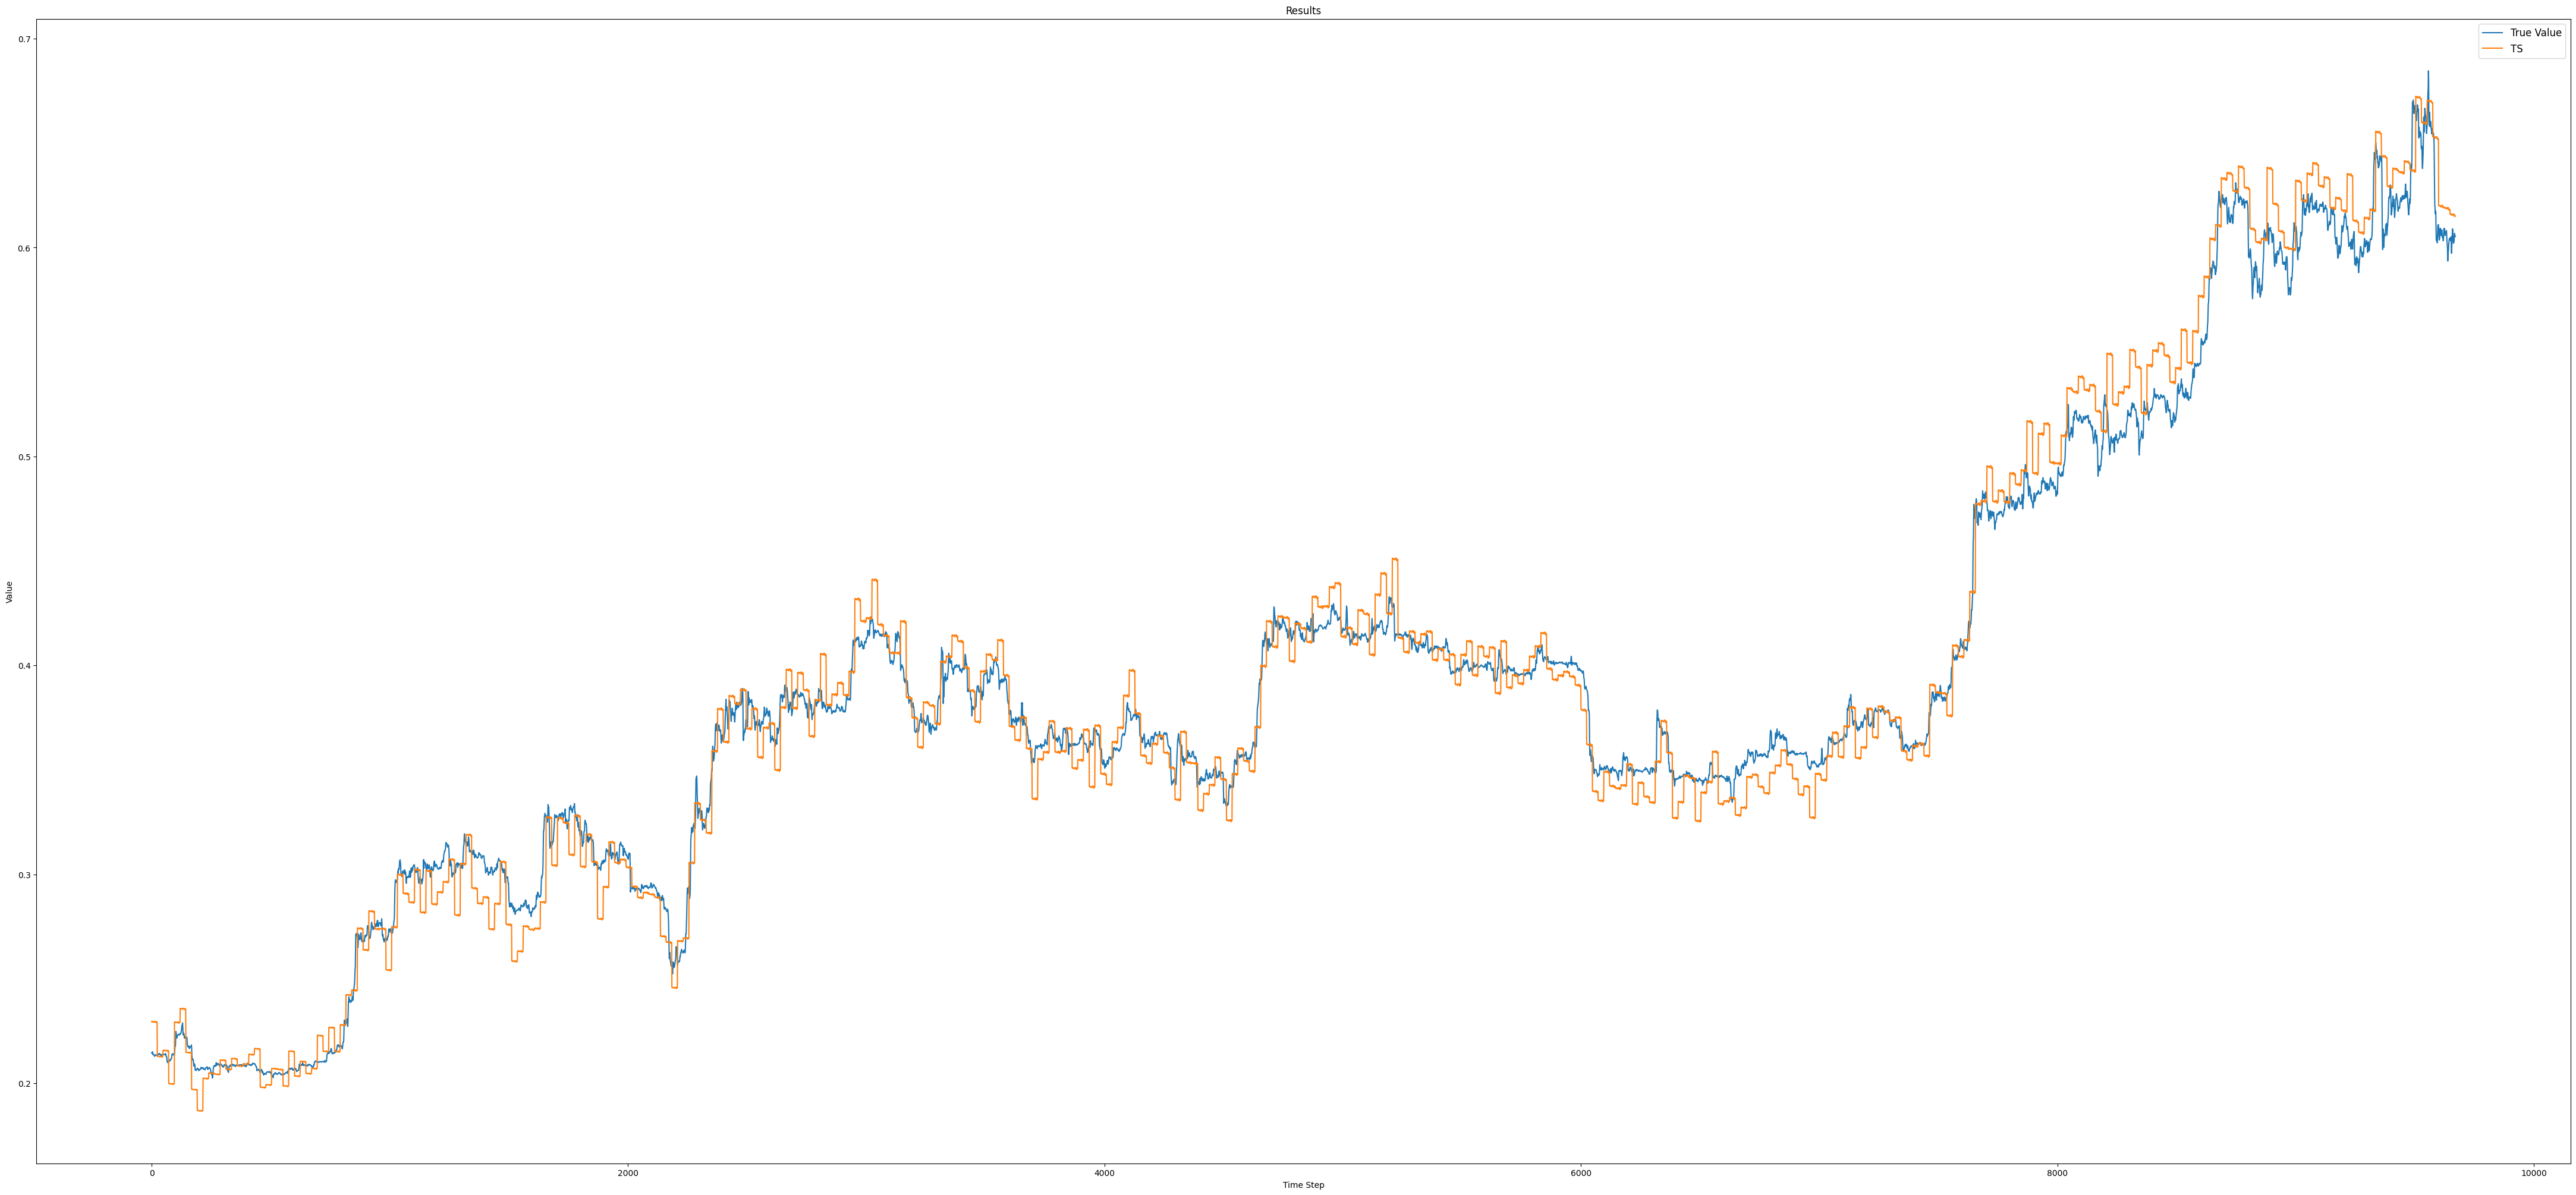

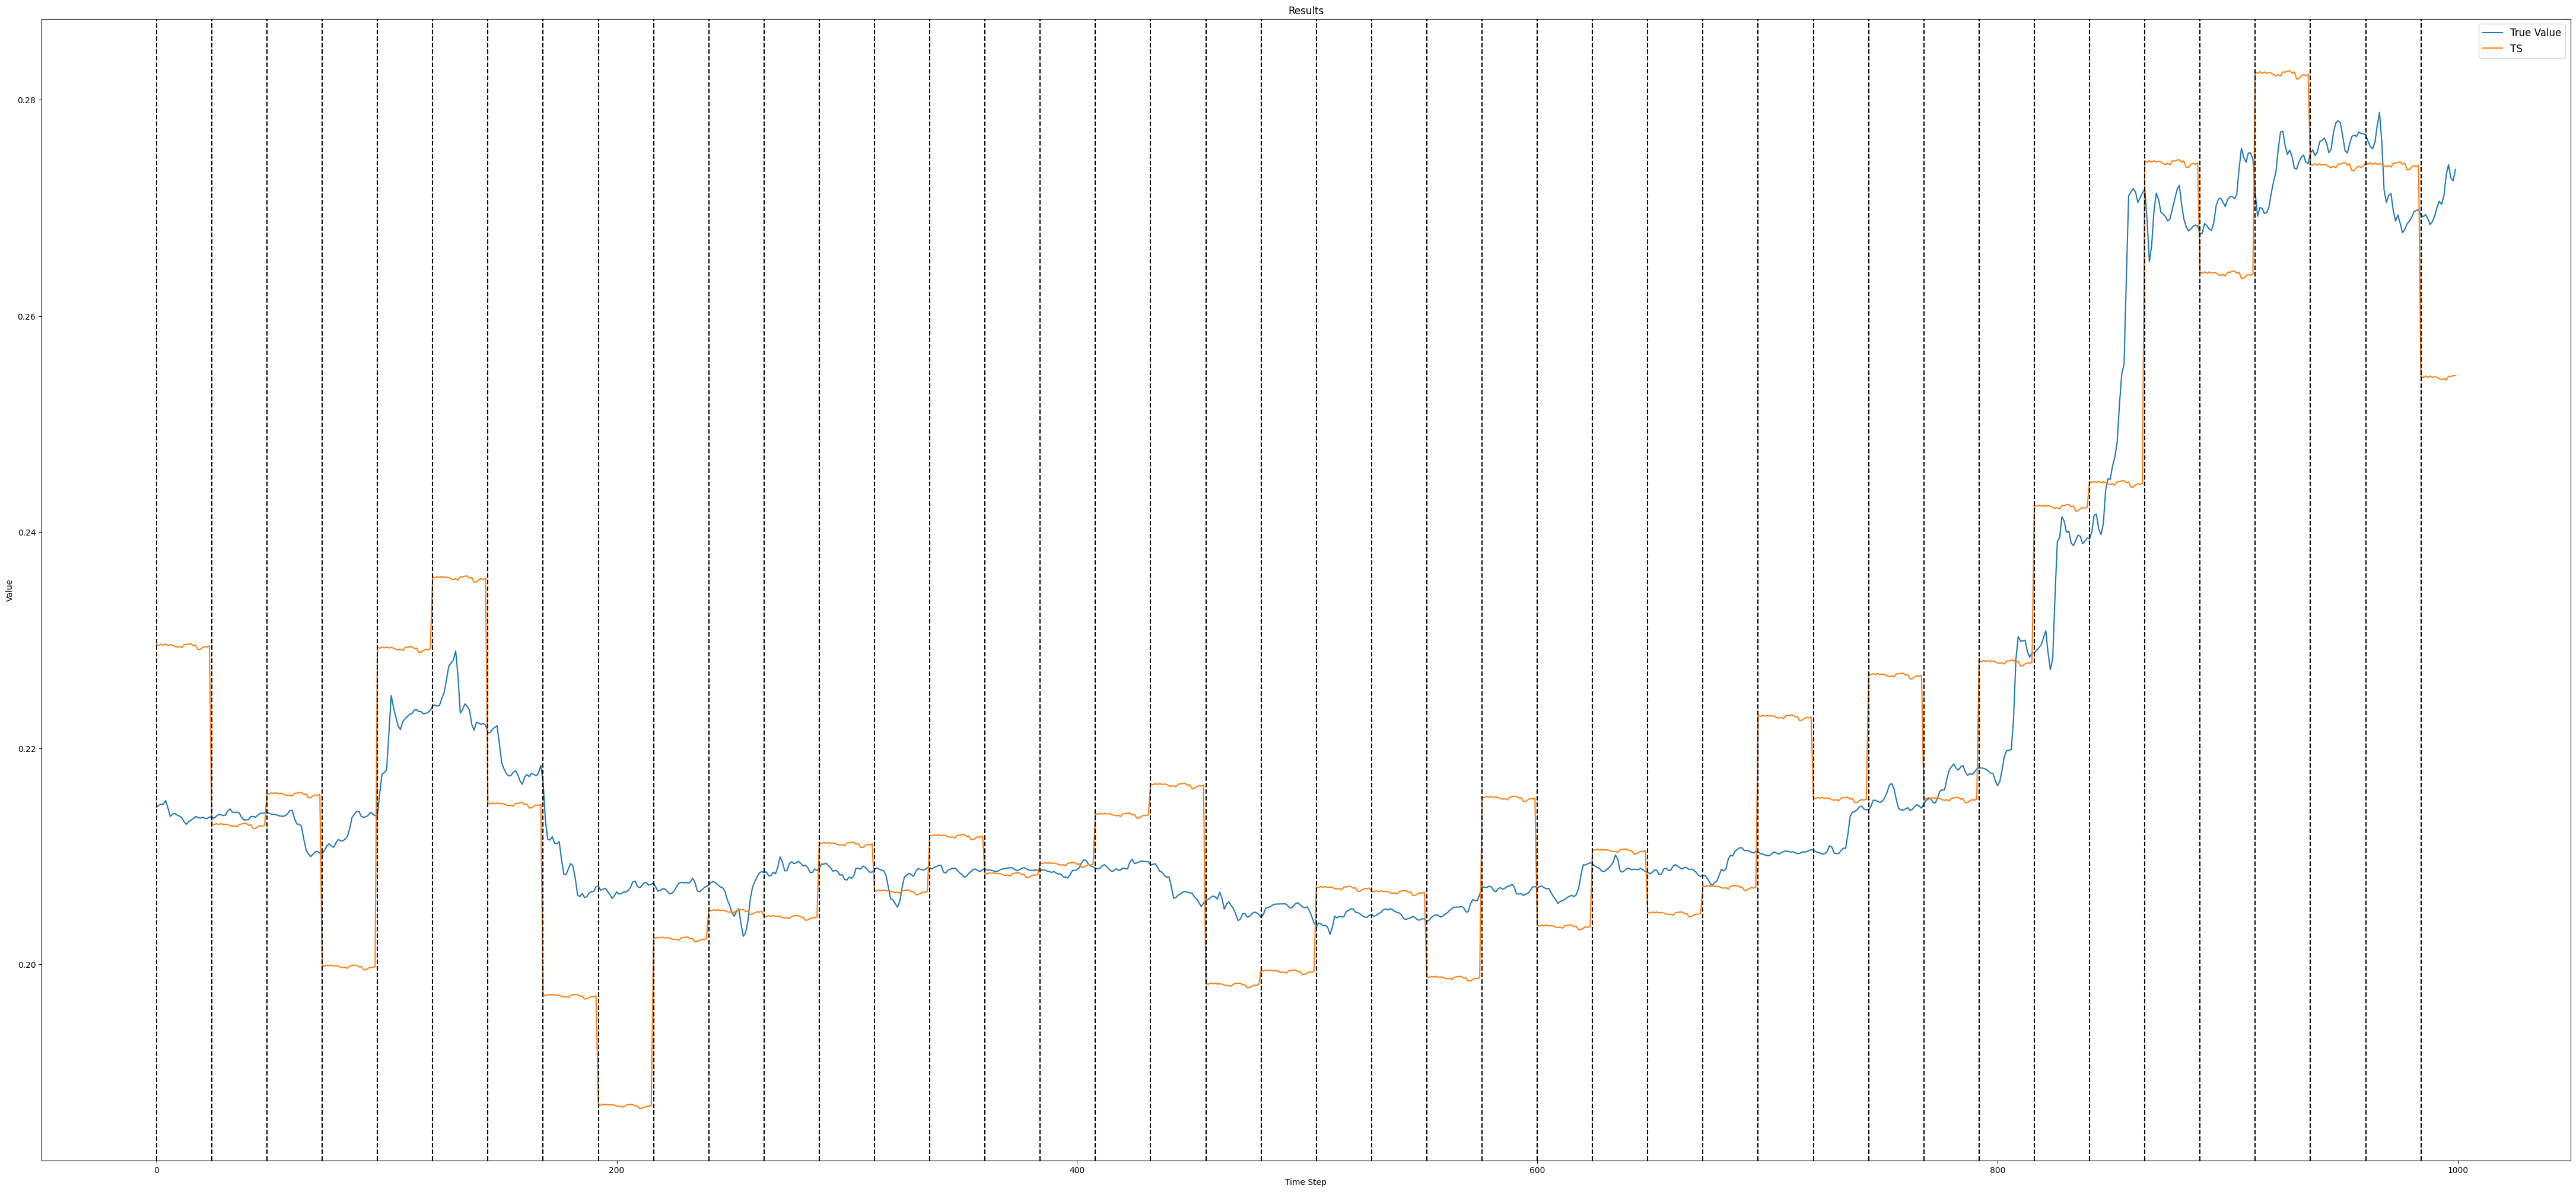

Mean MSE over dataset: 0.00017648296515817698


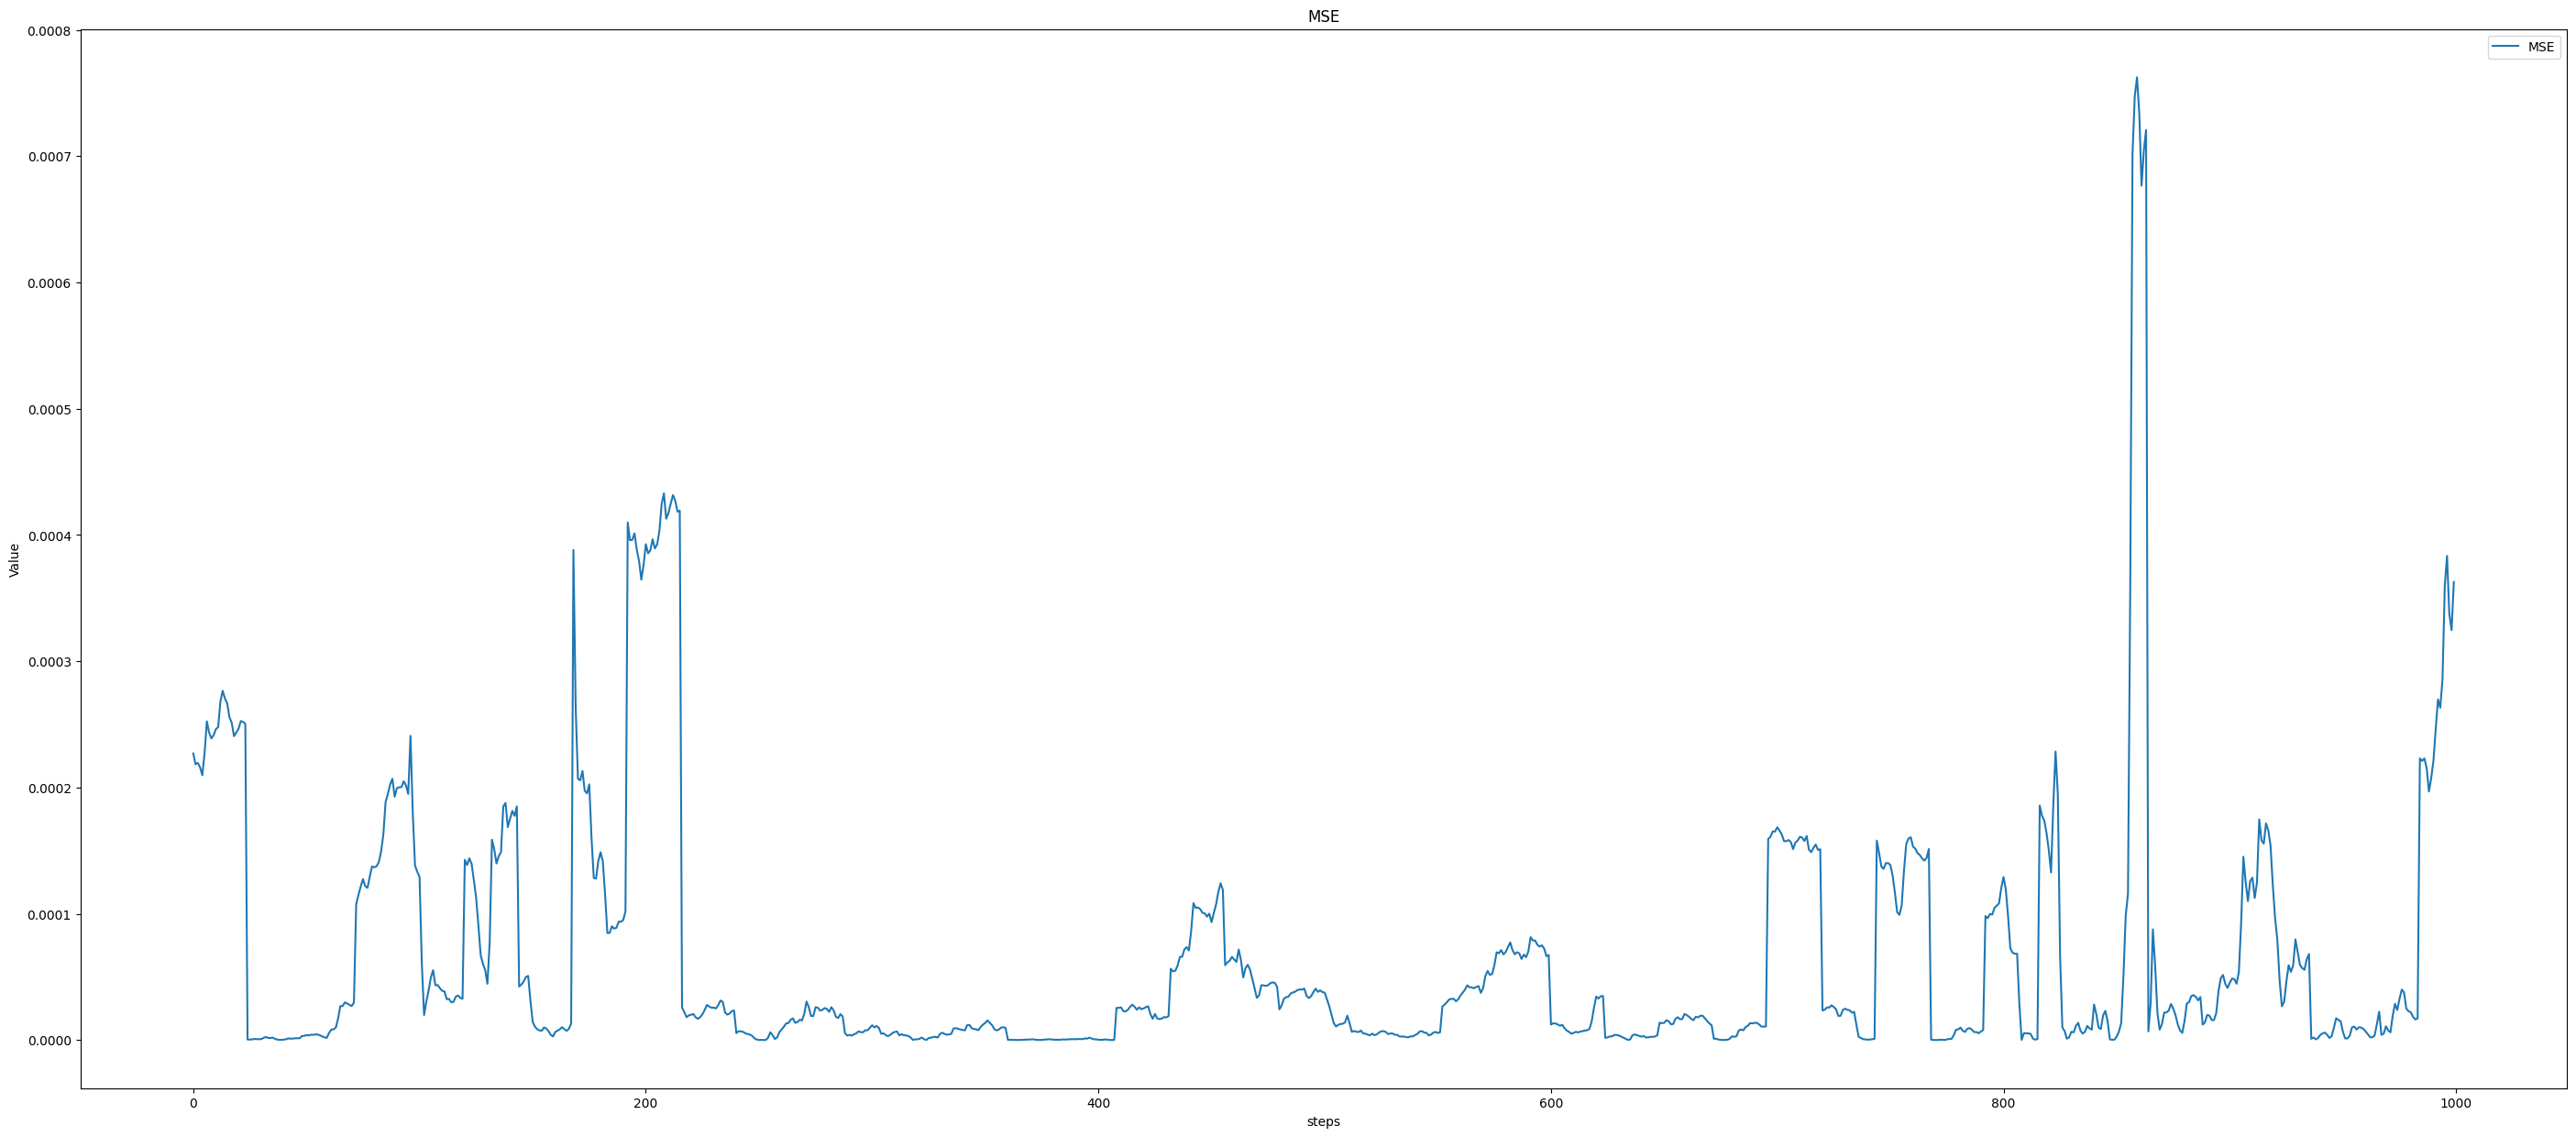

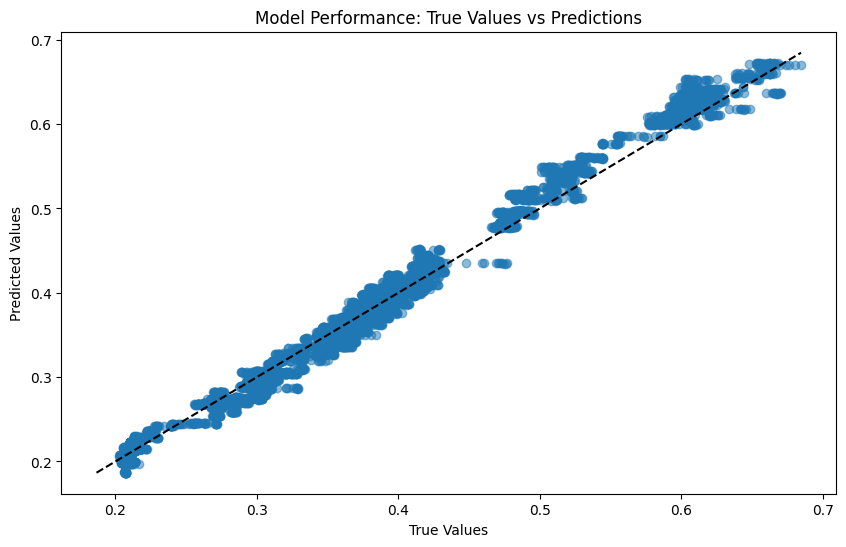

In [ ]:
predictionsPlot(resultTS,-1,-1,"TS")
predictionsPlot(resultTS,0,1000,"TS")
msePlot(0,1000,resultManagerTS,resultTS)
scatter(resultTS)


Riga selezionata:
[1, 2, 3, 4, 5]

Colonna selezionata:
0         [1, 2, 3, 4, 5]
1    [10, 20, 30, 40, 50]
2               [7, 8, 9]
Name: A, dtype: object
